In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
df = pd.read_csv("recommendation_dataset.csv")
print(df.shape)
df.head()

(3676, 7)


,title,type,release_year,genre,description,imdb_rating,votes
0,The Shawshank Redemption,Movie,1994,Drama,Two imprisoned men bond over a number of years...,9.3,2343110.0
1,The Godfather,Movie,1972,"Crime, Drama",An organized crime dynasty's aging patriarch t...,9.2,1620367.0
2,The Dark Knight,Movie,2008,"Action, Crime, Drama",When the menace known as the Joker wreaks havo...,9.0,2303232.0
3,The Godfather: Part II,Movie,1974,"Crime, Drama",The early life and career of Vito Corleone in ...,9.0,1129952.0
4,12 Angry Men,Movie,1957,"Crime, Drama",A jury holdout attempts to prevent a miscarria...,9.0,689845.0


In [3]:
movies = df[df["type"] == "Movie"].reset_index(drop=True)
shows = df[df["type"] == "TV Show"].reset_index(drop=True)

print("Movies:", len(movies))
print("TV Shows:", len(shows))

Movies: 1000
TV Shows: 2676


In [5]:
# Separate individual genres
genre_df = df.assign(
    genre=df["genre"].str.split(", ")
).explode("genre").reset_index(drop=True)

# Select genres represented in both datasets
movie_genres = set(
    genre_df[genre_df["type"] == "Movie"]["genre"]
)

show_genres = set(
    genre_df[genre_df["type"] == "TV Show"]["genre"]
)

shared_genres = movie_genres.intersection(show_genres)

genre_df = genre_df[
    genre_df["genre"].isin(shared_genres)
].reset_index(drop=True)

# Count genre appearances
genre_counts = pd.crosstab(
    genre_df["genre"],
    genre_df["type"]
)

# Convert to percentages of titles
genre_pct = genre_counts.div(
    df["type"].value_counts(), axis=1
) * 100

# Select top 10 shared genres
top_genres = genre_counts.sum(axis=1).nlargest(10).index

genre_pct = genre_pct.loc[top_genres]

genre_pct.round(2)

type,Movie,TV Show
genre,,
Drama,72.4,28.51
Comedy,23.3,21.71
Crime,20.9,17.56
Romance,12.5,13.83
Adventure,19.6,6.28
Action,18.9,6.28
Mystery,9.9,3.66
Thriller,13.7,2.13
Sci-Fi,6.7,3.14


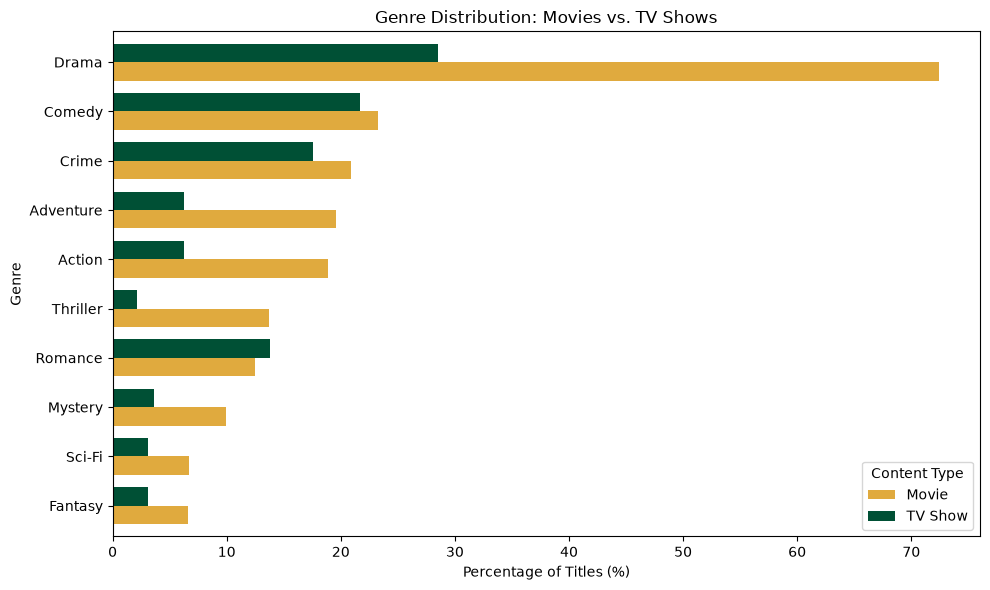

In [6]:
genre_pct.sort_values("Movie").plot(
    kind="barh",
    figsize=(10, 6),
    color=["#E0AA3E", "#005035"],
    width=0.75
)

plt.title("Genre Distribution: Movies vs. TV Shows")
plt.xlabel("Percentage of Titles (%)")
plt.ylabel("Genre")
plt.legend(title="Content Type")
plt.tight_layout()

plt.savefig("genre_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [7]:
mlb = MultiLabelBinarizer()

all_genres = df["genre"].str.split(", ")

mlb.fit(all_genres)

movie_genres = mlb.transform(
    movies["genre"].str.split(", ")
)

show_genres = mlb.transform(
    shows["genre"].str.split(", ")
)

print("Movie feature shape:", movie_genres.shape)
print("TV show feature shape:", show_genres.shape)

Movie feature shape: (1000, 34)
TV show feature shape: (2676, 34)


In [8]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

# Fit using the candidate TV show catalog
tfidf.fit(shows["description"])

movie_descriptions = tfidf.transform(
    movies["description"]
)

show_descriptions = tfidf.transform(
    shows["description"]
)

In [9]:
genre_similarity = cosine_similarity(
    movie_genres,
    show_genres
)

print(genre_similarity.shape)

(1000, 2676)


In [10]:
description_similarity = cosine_similarity(
    movie_descriptions,
    show_descriptions
)

In [11]:
hybrid_similarity = (
    0.5 * genre_similarity +
    0.5 * description_similarity
)

In [12]:
rng = np.random.default_rng(42)

random_similarity = rng.random(
    (len(movies), len(shows))
)

In [13]:
def recommend_shows(movie_title, similarity_matrix, n=5):

    matches = movies.index[
        movies["title"].str.lower() == movie_title.lower()
    ]

    if len(matches) == 0:
        return "Movie not found."

    movie_index = matches[0]

    scores = similarity_matrix[movie_index]

    top_indices = np.argsort(scores)[::-1][:n]

    recommendations = shows.iloc[top_indices][[
        "title",
        "genre",
        "description"
    ]].copy()

    recommendations["similarity_score"] = scores[top_indices]

    return recommendations.reset_index(drop=True)

In [14]:
recommend_shows(
    "The Dark Knight",
    genre_similarity
)

,title,genre,description,similarity_score
0,Marvel's Iron Fist,"Crime, Action, Adventure, Drama",Danny Rand resurfaces 15 years after being pre...,0.866025
1,Marvel's Luke Cage,"Crime, Action, Adventure, Drama","A hoodie-wearing, unbreakable ex-con fights to...",0.866025
2,Marvel's The Defenders,"Crime, Action, Adventure, Drama","Daredevil, Jessica Jones, Luke Cage and Iron F...",0.866025
3,Marvel's Jessica Jones,"Crime, Action, Adventure, Drama","Haunted by a traumatic past, Jessica Jones use...",0.866025
4,Shooter,"Crime, Action, Adventure, Drama",A highly decorated ex-Marine sniper returns to...,0.866025


In [15]:
recommend_shows(
    "The Dark Knight",
    description_similarity
)

,title,genre,description,similarity_score
0,Disenchantment,"Action, Adventure, Comedy, Sci-Fi, Fantasy","Princess duties call, but she'd rather be drin...",0.181390
1,Into the Night,"International TV Shows, Drama, Mystery",Passengers and crew aboard a hijacked overnigh...,0.167006
2,EDENS ZERO,"Anime Series, International TV Shows","Aboard the Edens Zero, a lonely boy with the a...",0.154446
3,Gypsy,Drama,Therapist Jean Holloway develops dangerous and...,0.127868
4,Brews Brothers,Comedy,Two rival brothers must work together to keep ...,0.122262


In [16]:
recommend_shows(
    "The Dark Knight",
    hybrid_similarity
)

,title,genre,description,similarity_score
0,Gotham,"Crime, Action, Adventure, Drama","Long before he was commissioner, rookie cop Ja...",0.488198
1,Marvel's Luke Cage,"Crime, Action, Adventure, Drama","A hoodie-wearing, unbreakable ex-con fights to...",0.473216
2,Queen of the South,"Crime, Action, Adventure, Drama",Forced to work for a cartel that recently kill...,0.433013
3,Marvel's The Defenders,"Crime, Action, Adventure, Drama","Daredevil, Jessica Jones, Luke Cage and Iron F...",0.433013
4,Marvel's Iron Fist,"Crime, Action, Adventure, Drama",Danny Rand resurfaces 15 years after being pre...,0.433013


In [25]:
recommend_shows(
    "Harry Potter",
    hybrid_similarity
)

'Movie not found.'

In [20]:
def evaluate_model(similarity_matrix, k=5):

    genre_matches = []
    description_scores = []
    diversity_scores = []

    for i in range(len(movies)):

        top_indices = np.argsort(
            similarity_matrix[i]
        )[::-1][:k]

        # Genre Match@5
        matches = (
            genre_similarity[i, top_indices] > 0
        )

        genre_matches.append(matches.mean())

        # Description Similarity@5
        description_scores.append(
            description_similarity[i, top_indices].mean()
        )

        # Recommendation Diversity@5
        recommended_genres = show_genres[top_indices]

        pairwise_scores = cosine_similarity(
            recommended_genres
        )

        upper_triangle = np.triu_indices(k, k=1)

        diversity = (
            1 - pairwise_scores[upper_triangle].mean()
        )

        diversity_scores.append(diversity)

    return {
        "Genre Match": np.mean(genre_matches),
        "Description Similarity": np.mean(description_scores),
        "Diversity": np.mean(diversity_scores)
    }

In [21]:
results = pd.DataFrame({
    "Random Baseline": evaluate_model(random_similarity),
    "Genre-Based": evaluate_model(genre_similarity),
    "Description-Based": evaluate_model(description_similarity),
    "Hybrid": evaluate_model(hybrid_similarity)
}).T

results.index.name = "Model"

results.round(3)

,Genre Match,Description Similarity,Diversity
Model,,,
Random Baseline,0.295,0.006,0.786
Genre-Based,0.996,0.009,0.066
Description-Based,0.431,0.186,0.711
Hybrid,0.996,0.050,0.098
